# Mammography Data Analysis & Knowledge Discovery

## 1. Project Overview

This project aims to extract meaningful knowledge from mammography clinical data and develop machine learning models to classify breast masses as benign or malignant.

The extracted knowledge will also be represented through a data-driven semantic graph.

## 2. Objectives

- Understand and explore the mammography dataset.
- Prepare and clean clinical data.
- Discover meaningful patterns and relationships.
- Develop machine learning classification models.
- Build a semantic graph to represent the extracted knowledge.

## 3. Dataset

This project uses the CBIS-DDSM dataset, which contains two main types of mammographic abnormalities:

- **Mass cases:** Clinical descriptors related to breast masses.
- **Calcification cases:** Clinical descriptors related to breast calcifications.

Both datasets include benign and malignant cases and will be analyzed to discover patterns and develop classification models.

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def go_line() :
    return  '\n============================'

## 4. Loading the Datasets

In this section, we load the training datasets for both mammographic masses and calcifications to inspect and compare their structures.

In [20]:
mass_df = pd.read_csv("../data/mass_case_description_train_set.csv")
calc_df = pd.read_csv("../data/calc_case_description_train_set.csv")

print("Mass dataset:", mass_df.shape)
display(mass_df.head(8))

print (go_line())

print("Calcification dataset:", calc_df.shape)
display(calc_df.head(6))

Mass dataset: (1318, 14)


,patient_id,breast_density,left or right breast,image view,abnormality id,abnormality type,mass shape,mass margins,assessment,pathology,subtlety,image file path,cropped image file path,ROI mask file path
0,P_00001,3,LEFT,CC,1,mass,IRREGULAR-ARCHITECTURAL_DISTORTION,SPICULATED,4,MALIGNANT,4,Mass-Training_P_00001_LEFT_CC/1.3.6.1.4.1.9590...,Mass-Training_P_00001_LEFT_CC_1/1.3.6.1.4.1.95...,Mass-Training_P_00001_LEFT_CC_1/1.3.6.1.4.1.95...
1,P_00001,3,LEFT,MLO,1,mass,IRREGULAR-ARCHITECTURAL_DISTORTION,SPICULATED,4,MALIGNANT,4,Mass-Training_P_00001_LEFT_MLO/1.3.6.1.4.1.959...,Mass-Training_P_00001_LEFT_MLO_1/1.3.6.1.4.1.9...,Mass-Training_P_00001_LEFT_MLO_1/1.3.6.1.4.1.9...
2,P_00004,3,LEFT,CC,1,mass,ARCHITECTURAL_DISTORTION,ILL_DEFINED,4,BENIGN,3,Mass-Training_P_00004_LEFT_CC/1.3.6.1.4.1.9590...,Mass-Training_P_00004_LEFT_CC_1/1.3.6.1.4.1.95...,Mass-Training_P_00004_LEFT_CC_1/1.3.6.1.4.1.95...
3,P_00004,3,LEFT,MLO,1,mass,ARCHITECTURAL_DISTORTION,ILL_DEFINED,4,BENIGN,3,Mass-Training_P_00004_LEFT_MLO/1.3.6.1.4.1.959...,Mass-Training_P_00004_LEFT_MLO_1/1.3.6.1.4.1.9...,Mass-Training_P_00004_LEFT_MLO_1/1.3.6.1.4.1.9...
4,P_00004,3,RIGHT,MLO,1,mass,OVAL,CIRCUMSCRIBED,4,BENIGN,5,Mass-Training_P_00004_RIGHT_MLO/1.3.6.1.4.1.95...,Mass-Training_P_00004_RIGHT_MLO_1/1.3.6.1.4.1....,Mass-Training_P_00004_RIGHT_MLO_1/1.3.6.1.4.1....
5,P_00009,3,RIGHT,CC,1,mass,OVAL,ILL_DEFINED,4,MALIGNANT,4,Mass-Training_P_00009_RIGHT_CC/1.3.6.1.4.1.959...,Mass-Training_P_00009_RIGHT_CC_1/1.3.6.1.4.1.9...,Mass-Training_P_00009_RIGHT_CC_1/1.3.6.1.4.1.9...
6,P_00009,3,RIGHT,MLO,1,mass,OVAL,ILL_DEFINED,4,MALIGNANT,4,Mass-Training_P_00009_RIGHT_MLO/1.3.6.1.4.1.95...,Mass-Training_P_00009_RIGHT_MLO_1/1.3.6.1.4.1....,Mass-Training_P_00009_RIGHT_MLO_1/1.3.6.1.4.1....
7,P_00015,3,LEFT,MLO,1,mass,IRREGULAR,ILL_DEFINED-SPICULATED,4,MALIGNANT,4,Mass-Training_P_00015_LEFT_MLO/1.3.6.1.4.1.959...,Mass-Training_P_00015_LEFT_MLO_1/1.3.6.1.4.1.9...,Mass-Training_P_00015_LEFT_MLO_1/1.3.6.1.4.1.9...



Calcification dataset: (1546, 14)


,patient_id,breast density,left or right breast,image view,abnormality id,abnormality type,calc type,calc distribution,assessment,pathology,subtlety,image file path,cropped image file path,ROI mask file path
0,P_00005,3,RIGHT,CC,1,calcification,AMORPHOUS,CLUSTERED,3,MALIGNANT,3,Calc-Training_P_00005_RIGHT_CC/1.3.6.1.4.1.959...,Calc-Training_P_00005_RIGHT_CC_1/1.3.6.1.4.1.9...,Calc-Training_P_00005_RIGHT_CC_1/1.3.6.1.4.1.9...
1,P_00005,3,RIGHT,MLO,1,calcification,AMORPHOUS,CLUSTERED,3,MALIGNANT,3,Calc-Training_P_00005_RIGHT_MLO/1.3.6.1.4.1.95...,Calc-Training_P_00005_RIGHT_MLO_1/1.3.6.1.4.1....,Calc-Training_P_00005_RIGHT_MLO_1/1.3.6.1.4.1....
2,P_00007,4,LEFT,CC,1,calcification,PLEOMORPHIC,LINEAR,4,BENIGN,4,Calc-Training_P_00007_LEFT_CC/1.3.6.1.4.1.9590...,Calc-Training_P_00007_LEFT_CC_1/1.3.6.1.4.1.95...,Calc-Training_P_00007_LEFT_CC_1/1.3.6.1.4.1.95...
3,P_00007,4,LEFT,MLO,1,calcification,PLEOMORPHIC,LINEAR,4,BENIGN,4,Calc-Training_P_00007_LEFT_MLO/1.3.6.1.4.1.959...,Calc-Training_P_00007_LEFT_MLO_1/1.3.6.1.4.1.9...,Calc-Training_P_00007_LEFT_MLO_1/1.3.6.1.4.1.9...
4,P_00008,1,LEFT,CC,1,calcification,NaN,REGIONAL,2,BENIGN_WITHOUT_CALLBACK,3,Calc-Training_P_00008_LEFT_CC/1.3.6.1.4.1.9590...,Calc-Training_P_00008_LEFT_CC_1/1.3.6.1.4.1.95...,Calc-Training_P_00008_LEFT_CC_1/1.3.6.1.4.1.95...
5,P_00008,1,LEFT,CC,2,calcification,NaN,REGIONAL,2,BENIGN_WITHOUT_CALLBACK,3,Calc-Training_P_00008_LEFT_CC/1.3.6.1.4.1.9590...,Calc-Training_P_00008_LEFT_CC_2/1.3.6.1.4.1.95...,Calc-Training_P_00008_LEFT_CC_2/1.3.6.1.4.1.95...


## 5. Comparing Dataset Features

In this section, we compare the columns of the mass and calcification datasets to identify their common features and specific clinical descriptors.

In [8]:
print("Mass columns:")
print(mass_df.columns.tolist())

print("\nCalcification columns:")
print(calc_df.columns.tolist())

Mass columns:
['patient_id', 'breast_density', 'left or right breast', 'image view', 'abnormality id', 'abnormality type', 'mass shape', 'mass margins', 'assessment', 'pathology', 'subtlety', 'image file path', 'cropped image file path', 'ROI mask file path']

Calcification columns:
['patient_id', 'breast density', 'left or right breast', 'image view', 'abnormality id', 'abnormality type', 'calc type', 'calc distribution', 'assessment', 'pathology', 'subtlety', 'image file path', 'cropped image file path', 'ROI mask file path']


## 6. Data Types Inspection

We inspect the data types of both datasets to identify numerical, categorical, and identifier columns before preprocessing.

In [13]:
print("MASS DATASET: ")
mass_df.info()
print (go_line())
print("\nCALCIFICATION DATASET: ")
calc_df.info()

MASS DATASET: 
<class 'pandas.DataFrame'>
RangeIndex: 1318 entries, 0 to 1317
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   patient_id               1318 non-null   str  
 1   breast_density           1318 non-null   int64
 2   left or right breast     1318 non-null   str  
 3   image view               1318 non-null   str  
 4   abnormality id           1318 non-null   int64
 5   abnormality type         1318 non-null   str  
 6   mass shape               1314 non-null   str  
 7   mass margins             1275 non-null   str  
 8   assessment               1318 non-null   int64
 9   pathology                1318 non-null   str  
 10  subtlety                 1318 non-null   int64
 11  image file path          1318 non-null   str  
 12  cropped image file path  1318 non-null   str  
 13  ROI mask file path       1318 non-null   str  
dtypes: int64(4), str(10)
memory usage: 144.3 KB


CALCIF

## 7. Missing Values Analysis

In this section, we identify and quantify missing values in both datasets to determine which features require data cleaning and preprocessing.

In [27]:
print("MASS DATASET: ")
print (mass_df.isna().sum())

print("\nCALCIFICATION DATASET: ")
print (calc_df.isna().sum())

MASS DATASET: 
patient_id                  0
breast_density              0
left or right breast        0
image view                  0
abnormality id              0
abnormality type            0
mass shape                  4
mass margins               43
assessment                  0
pathology                   0
subtlety                    0
image file path             0
cropped image file path     0
ROI mask file path          0
dtype: int64

CALCIFICATION DATASET: 
patient_id                   0
breast density               0
left or right breast         0
image view                   0
abnormality id               0
abnormality type             0
calc type                   20
calc distribution          376
assessment                   0
pathology                    0
subtlety                     0
image file path              0
cropped image file path      0
ROI mask file path           0
dtype: int64


## 8. Missing Values Visualization

This section visualizes the percentage of missing values in the clinical descriptors of both datasets to identify features that may require special preprocessing.

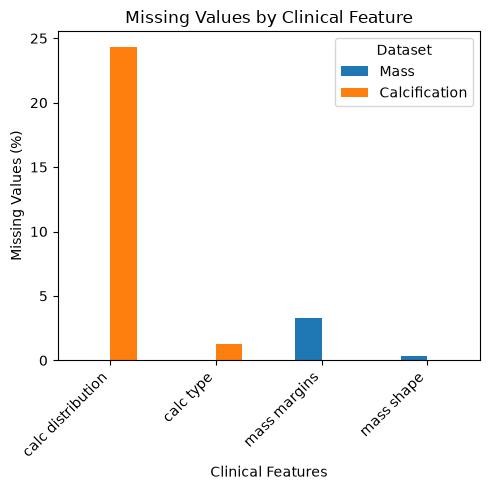

In [34]:
missing = pd.DataFrame({
    "Mass": mass_df.isnull().mean() * 100,
    "Calcification": calc_df.isnull().mean() * 100
})

missing = missing.loc[missing.max(axis=1) > 0]

missing.plot(kind="bar", figsize=(5, 5))

plt.title("Missing Values by Clinical Feature")
plt.ylabel("Missing Values (%)")
plt.xlabel("Clinical Features")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Dataset")
plt.tight_layout()
plt.show()

### Key Findings

- The mass dataset contains a small number of missing values in `mass shape` and `mass margins`.
- The calcification dataset has a significant proportion of missing values in `calc distribution` (24.32%).
- Missing values will be investigated and handled during the data preprocessing stage.

## 9. Target Variable Distribution

In this section, we analyze the distribution of the target variable `pathology` in both datasets to understand the proportion of benign and malignant cases and identify potential class imbalance.

In [36]:
print("MASS DATASET: ")
print(mass_df["pathology"].value_counts())

print("\nCALCIFICATION DATASET: ")
print(calc_df["pathology"].value_counts())

MASS DATASET: 
pathology
MALIGNANT                  637
BENIGN                     577
BENIGN_WITHOUT_CALLBACK    104
Name: count, dtype: int64

CALCIFICATION DATASET: 
pathology
MALIGNANT                  544
BENIGN                     528
BENIGN_WITHOUT_CALLBACK    474
Name: count, dtype: int64


## 10. Target Distribution Visualization

This section compares the distribution of pathology classes in the mass and calcification datasets using bar charts.

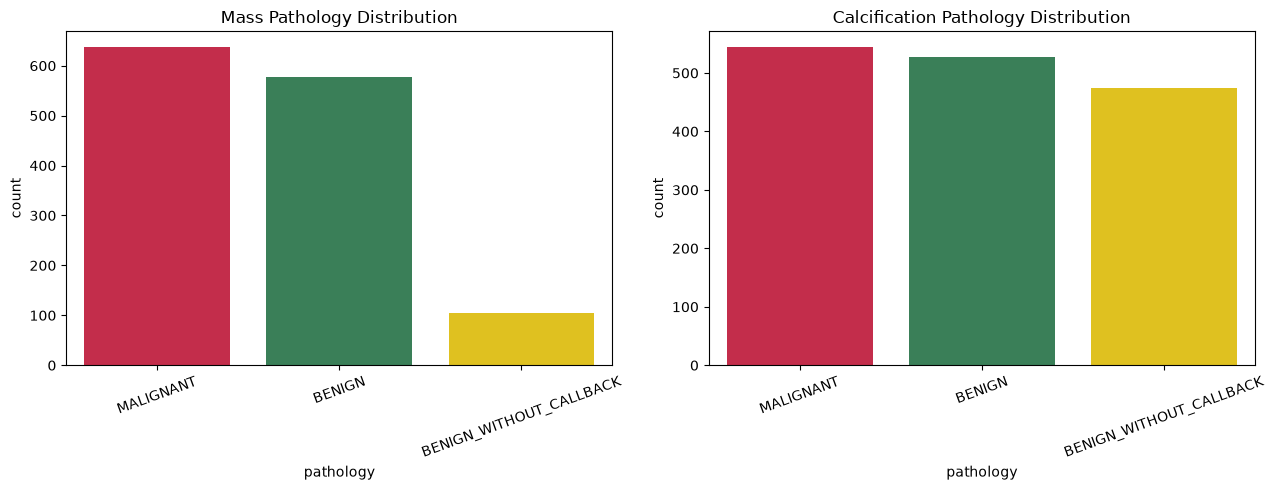

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

palette = {
    "MALIGNANT": "crimson",
    "BENIGN": "seagreen",
    "BENIGN_WITHOUT_CALLBACK": "gold"
}

sns.countplot(
    data=mass_df,
    x="pathology",
    hue="pathology",
    palette=palette,
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Mass Pathology Distribution")
axes[0].tick_params(axis="x", rotation=20)

sns.countplot(
    data=calc_df,
    x="pathology",
    hue="pathology",
    palette=palette,
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Calcification Pathology Distribution")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

## 11. Clinical Features Distribution

In this section, we explore the distribution of clinical descriptors for mammographic masses and calcifications to understand the characteristics of each abnormality type.

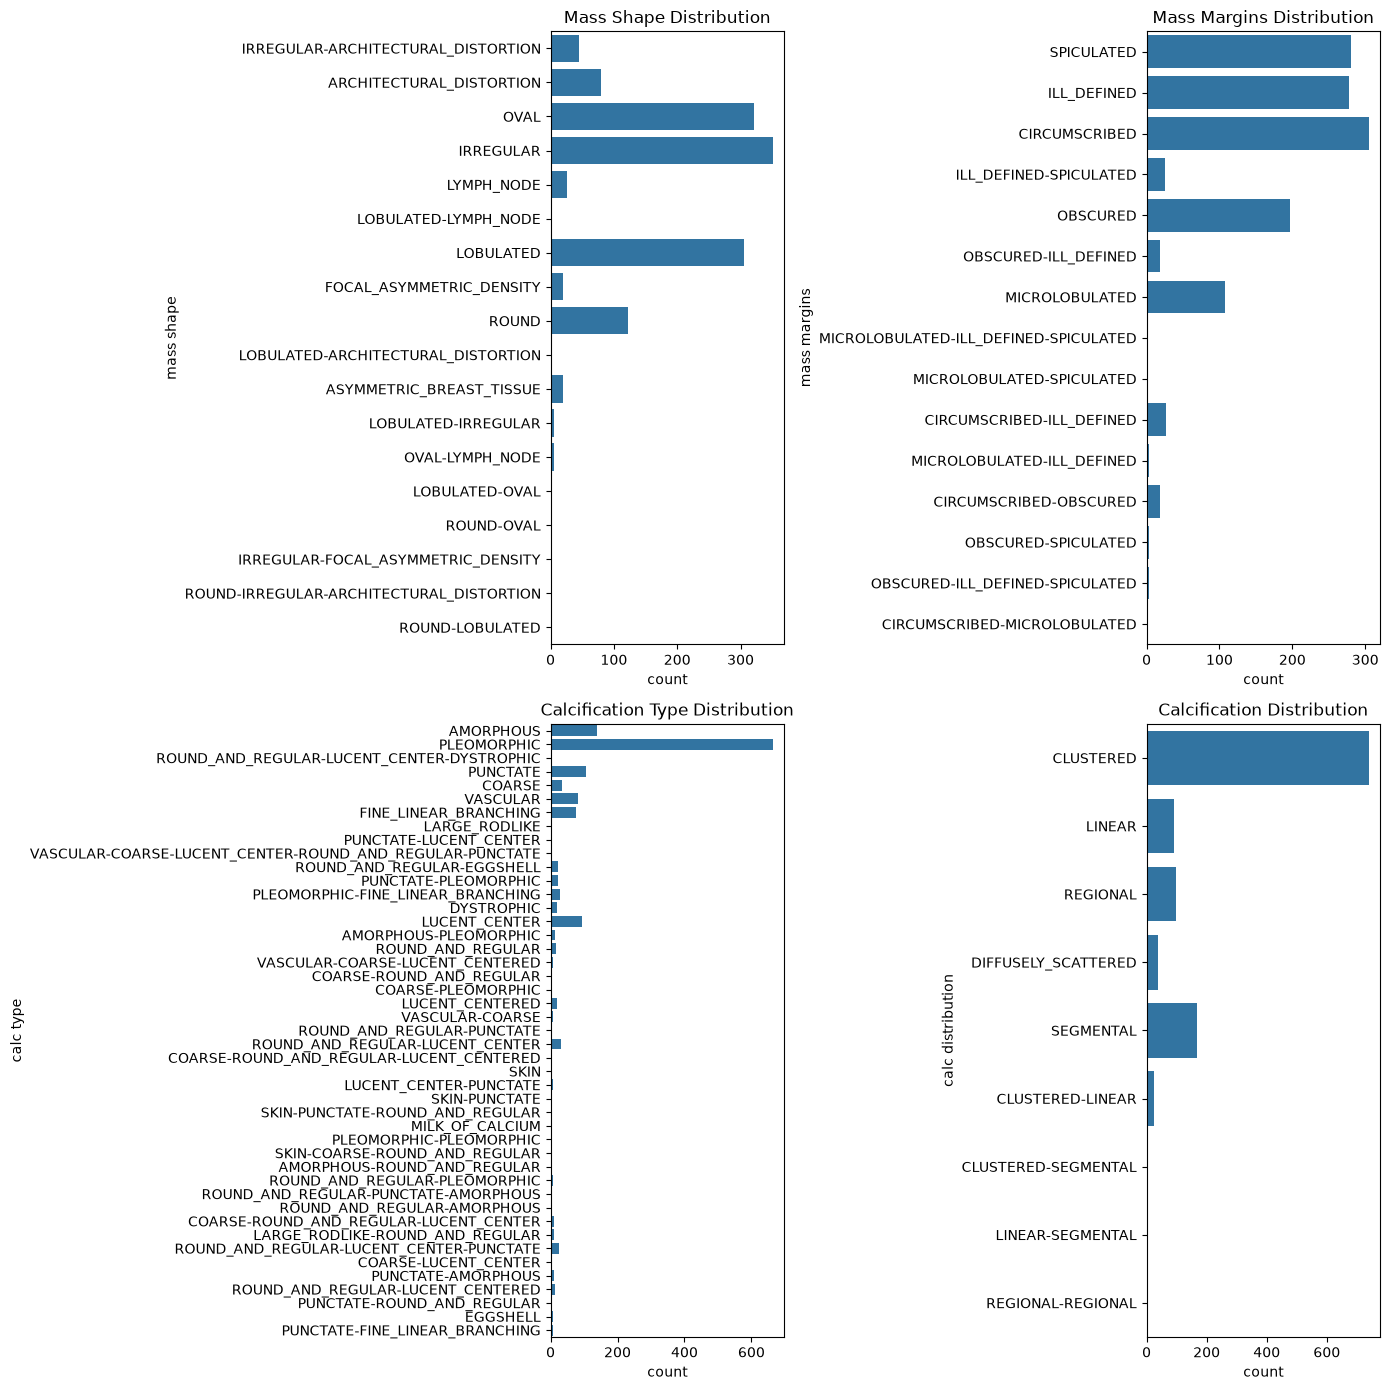

In [42]:
fig, axes = plt.subplots(2, 2, figsize=(14, 14))

sns.countplot(data=mass_df, y="mass shape", ax=axes[0, 0])
axes[0, 0].set_title("Mass Shape Distribution")

sns.countplot(data=mass_df, y="mass margins", ax=axes[0, 1])
axes[0, 1].set_title("Mass Margins Distribution")

sns.countplot(data=calc_df, y="calc type", ax=axes[1, 0])
axes[1, 0].set_title("Calcification Type Distribution")

sns.countplot(data=calc_df, y="calc distribution", ax=axes[1, 1])
axes[1, 1].set_title("Calcification Distribution")

plt.tight_layout()
plt.show()

### Key Findings

- Mass cases are described using `mass shape` and `mass margins`.
- Calcification cases are described using `calc type` and `calc distribution`.
- The distributions of clinical descriptors provide an overview of the most frequent abnormality characteristics.

## 12. Duplicate Records Analysis

In this section, we identify duplicate records and repeated patient identifiers in both datasets to better understand the data structure and detect potential data quality issues.

In [45]:
print("MASS DATASET: ")
print("Duplicate rows:", mass_df.duplicated().sum())
print("Unique patients:", mass_df["patient_id"].nunique())
print("Repeated patient IDs:", mass_df["patient_id"].duplicated().sum())

print("\nCALCIFICATION DATASET: ")
print("Duplicate rows:", calc_df.duplicated().sum())
print("Unique patients:", calc_df["patient_id"].nunique())
print("Repeated patient IDs:", calc_df["patient_id"].duplicated().sum())

MASS DATASET: 
Duplicate rows: 0
Unique patients: 691
Repeated patient IDs: 627

CALCIFICATION DATASET: 
Duplicate rows: 0
Unique patients: 602
Repeated patient IDs: 944


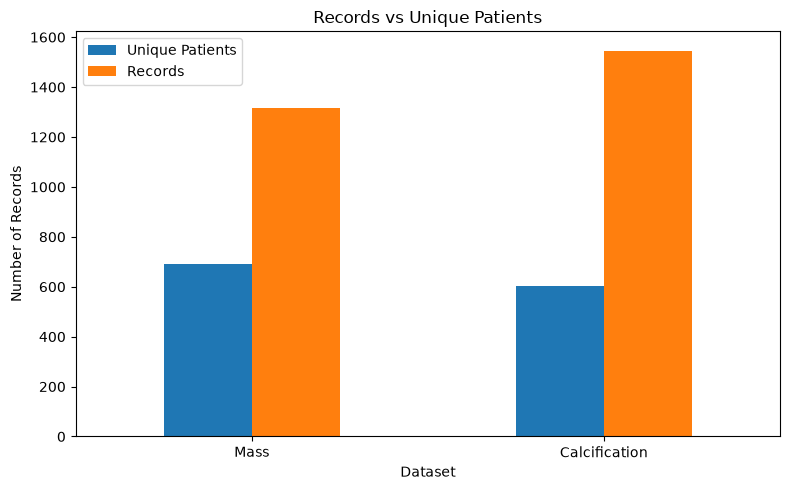

In [46]:
dup_data = pd.DataFrame({
    "Dataset": ["Mass", "Calcification"],
    "Unique Patients": [
        mass_df["patient_id"].nunique(),
        calc_df["patient_id"].nunique()
    ],
    "Records": [len(mass_df), len(calc_df)]
})

dup_data.set_index("Dataset").plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Records vs Unique Patients")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Key Findings

- No exact duplicate records were found.
- Both datasets contain multiple records associated with some patients.
- Repeated patient identifiers may represent multiple abnormalities or observations.
- Patient-level separation must be considered when splitting data for machine learning to avoid data leakage.

## 13. Unique Values Analysis

In this section, we inspect the unique values of categorical features in both datasets to identify inconsistent labels, unexpected categories, and potential data quality issues.

In [48]:
mass_cols = [
    "left or right breast",
    "image view",
    "abnormality type",
    "mass shape",
    "mass margins",
    "pathology"
]

calc_cols = [
    "left or right breast",
    "image view",
    "abnormality type",
    "calc type",
    "calc distribution",
    "pathology"
]

print("MASS DATASET: ")
for col in mass_cols:
    print(f"\n{col}:")
    print(mass_df[col].value_counts(dropna=False))

print("\nCALCIFICATION DATASET: ")
for col in calc_cols:
    print(f"\n{col}:")
    print(calc_df[col].value_counts(dropna=False))

MASS DATASET: 

left or right breast:
left or right breast
RIGHT    687
LEFT     631
Name: count, dtype: int64

image view:
image view
MLO    711
CC     607
Name: count, dtype: int64

abnormality type:
abnormality type
mass    1318
Name: count, dtype: int64

mass shape:
mass shape
IRREGULAR                                   351
OVAL                                        321
LOBULATED                                   305
ROUND                                       123
ARCHITECTURAL_DISTORTION                     80
IRREGULAR-ARCHITECTURAL_DISTORTION           45
LYMPH_NODE                                   26
ASYMMETRIC_BREAST_TISSUE                     20
FOCAL_ASYMMETRIC_DENSITY                     19
OVAL-LYMPH_NODE                               6
LOBULATED-IRREGULAR                           5
NaN                                           4
LOBULATED-LYMPH_NODE                          3
ROUND-OVAL                                    3
LOBULATED-ARCHITECTURAL_DISTORTION            

### Key Findings

- No obvious inconsistent capitalization was observed in categorical labels.
- Several clinical descriptors contain combined categories.
- Some labels appear similar and require semantic verification.
- Rare categories were identified and should not be removed without investigation.
- Missing values remain a major data quality concern, especially in calcification distribution.

## 14. Numeric Features Analysis

**Objective:** Analyze the numerical features of both datasets to understand their value distributions and identify potential anomalies.

The analysis focuses on three numerical features:

- `breast_density`
- `assessment`
- `subtlety`

We will examine the frequency of each value in the mass and calcification datasets.

In [53]:
calc_df = calc_df.rename(
    columns={"breast density": "breast_density"}
)

numeric_cols = [
    "breast_density",
    "assessment",
    "subtlety"
]

print("MASS DATASET")
for col in numeric_cols:
    print(f"\n{col}:")
    print(mass_df[col].value_counts().sort_index())

print("\nCALCIFICATION DATASET")
for col in numeric_cols:
    print(f"\n{col}:")
    print(calc_df[col].value_counts().sort_index())

MASS DATASET

breast_density:
breast_density
1    287
2    585
3    337
4    109
Name: count, dtype: int64

assessment:
assessment
0    129
1      1
2     77
3    279
4    533
5    299
Name: count, dtype: int64

subtlety:
subtlety
0      2
1     41
2    100
3    257
4    375
5    543
Name: count, dtype: int64

CALCIFICATION DATASET

breast_density:
breast_density
1    175
2    501
3    539
4    331
Name: count, dtype: int64

assessment:
assessment
0     63
2    482
3     89
4    753
5    159
Name: count, dtype: int64

subtlety:
subtlety
1     95
2    242
3    502
4    346
5    361
Name: count, dtype: int64


### Key Findings

- Both datasets contain breast density values ranging from 1 to 4.
- Assessment values range from 0 to 5 in both datasets.
- Mass subtlety values range from 0 to 5, while calcification subtlety values range from 1 to 5.
- Two mass records have a subtlety value of 0, which requires further investigation.
- The meaning and validity of zero values in assessment and subtlety should be verified before data cleaning.

## 15. Relationship Between Clinical Features and Pathology

**Objective:** Explore the relationship between clinical features and the target variable (`pathology`) to identify potential patterns associated with each pathology class.

We will compare the distributions of clinical features across the different pathology categories in both datasets.

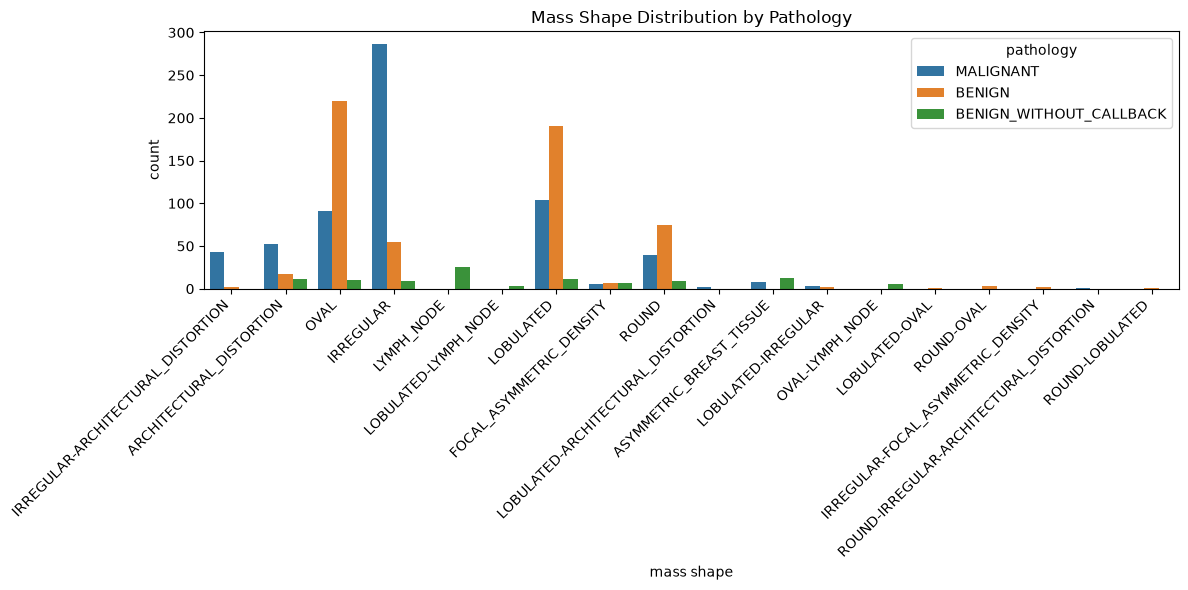

In [54]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=mass_df,
    x="mass shape",
    hue="pathology"
)

plt.title("Mass Shape Distribution by Pathology")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [62]:
pd.crosstab(
    mass_df["mass shape"],
    mass_df["pathology"]
)

pathology,BENIGN,BENIGN_WITHOUT_CALLBACK,MALIGNANT
mass shape,,,
ARCHITECTURAL_DISTORTION,17,11,52
ASYMMETRIC_BREAST_TISSUE,0,12,8
FOCAL_ASYMMETRIC_DENSITY,7,7,5
IRREGULAR,55,9,287
IRREGULAR-ARCHITECTURAL_DISTORTION,2,0,43
IRREGULAR-FOCAL_ASYMMETRIC_DENSITY,2,0,0
LOBULATED,190,11,104
LOBULATED-ARCHITECTURAL_DISTORTION,0,0,2
LOBULATED-IRREGULAR,2,0,3


### Key Findings

- Irregular-shaped masses are predominantly associated with malignant cases.
- Oval-shaped masses are more frequently associated with benign cases.
- Lobulated masses show a higher number of benign cases than malignant cases.
- Architectural distortion has a higher number of malignant cases than benign cases.
- Lymph node observations are classified as BENIGN_WITHOUT_CALLBACK in this dataset.

These observations highlight potential relationships between mass shape and pathology that can be further investigated during the knowledge discovery phase.

In [61]:
pd.crosstab(
    mass_df["mass margins"],
    mass_df["pathology"]
)

pathology,BENIGN,BENIGN_WITHOUT_CALLBACK,MALIGNANT
mass margins,,,
CIRCUMSCRIBED,226,47,32
CIRCUMSCRIBED-ILL_DEFINED,14,0,13
CIRCUMSCRIBED-MICROLOBULATED,1,0,0
CIRCUMSCRIBED-OBSCURED,18,0,1
ILL_DEFINED,93,10,175
ILL_DEFINED-SPICULATED,2,0,23
MICROLOBULATED,33,6,69
MICROLOBULATED-ILL_DEFINED,2,0,1
MICROLOBULATED-ILL_DEFINED-SPICULATED,0,0,2


### Key Findings

- Spiculated margins are strongly represented among malignant cases.
- Ill-defined margins show a higher number of malignant cases than benign cases.
- Circumscribed margins are predominantly associated with benign cases.
- Obscured margins are also more frequently observed in benign cases.
- Microlobulated margins show a higher number of malignant cases than benign cases.

These findings suggest that mass margins may provide useful information for understanding the relationship between clinical descriptors and pathology.

In [60]:
pd.crosstab(
    calc_df["calc type"],
    calc_df["pathology"]
)

pathology,BENIGN,BENIGN_WITHOUT_CALLBACK,MALIGNANT
calc type,,,
AMORPHOUS,83,0,55
AMORPHOUS-PLEOMORPHIC,6,0,6
AMORPHOUS-ROUND_AND_REGULAR,0,0,3
COARSE,3,32,0
COARSE-LUCENT_CENTER,0,2,0
COARSE-PLEOMORPHIC,2,0,0
COARSE-ROUND_AND_REGULAR,0,2,0
COARSE-ROUND_AND_REGULAR-LUCENT_CENTER,0,10,0
COARSE-ROUND_AND_REGULAR-LUCENT_CENTERED,0,4,0


### Key Findings

- Pleomorphic calcifications represent the largest category among malignant cases.
- Fine linear branching calcifications show a higher number of malignant cases than benign cases.
- Amorphous calcifications appear in both benign and malignant cases.
- Lucent center and vascular calcifications are predominantly represented in the BENIGN_WITHOUT_CALLBACK category.
- Coarse calcifications are also mostly associated with BENIGN_WITHOUT_CALLBACK cases.

These observations suggest potential relationships between calcification types and pathology, which can be further investigated during the knowledge discovery phase.

In [64]:
pd.crosstab(
    calc_df["calc distribution"],
    calc_df["pathology"]
)

pathology,BENIGN,BENIGN_WITHOUT_CALLBACK,MALIGNANT
calc distribution,,,
CLUSTERED,406,17,317
CLUSTERED-LINEAR,6,0,19
CLUSTERED-SEGMENTAL,5,0,0
DIFFUSELY_SCATTERED,8,26,3
LINEAR,20,9,61
LINEAR-SEGMENTAL,0,0,5
REGIONAL,15,42,42
REGIONAL-REGIONAL,1,0,0
SEGMENTAL,62,9,97


### Key Findings

- Clustered calcifications represent the most frequent distribution in the dataset.
- Linear calcifications show a higher number of malignant cases than benign cases.
- Segmental calcifications also show a higher number of malignant cases.
- Clustered-linear calcifications are more frequently observed in malignant cases.
- Regional calcifications have an equal number of benign and malignant cases.
- Diffusely scattered calcifications are predominantly represented in the BENIGN_WITHOUT_CALLBACK category.

These findings highlight potential relationships between calcification distribution and pathology.

## 16. Analysis of Common Numerical Features

**Objective:** Investigate the relationship between common numerical clinical features and pathology in both datasets.

The analysis focuses on:

- `breast_density`
- `assessment`
- `subtlety`

We will compare their distributions across the three pathology categories to identify potential patterns.

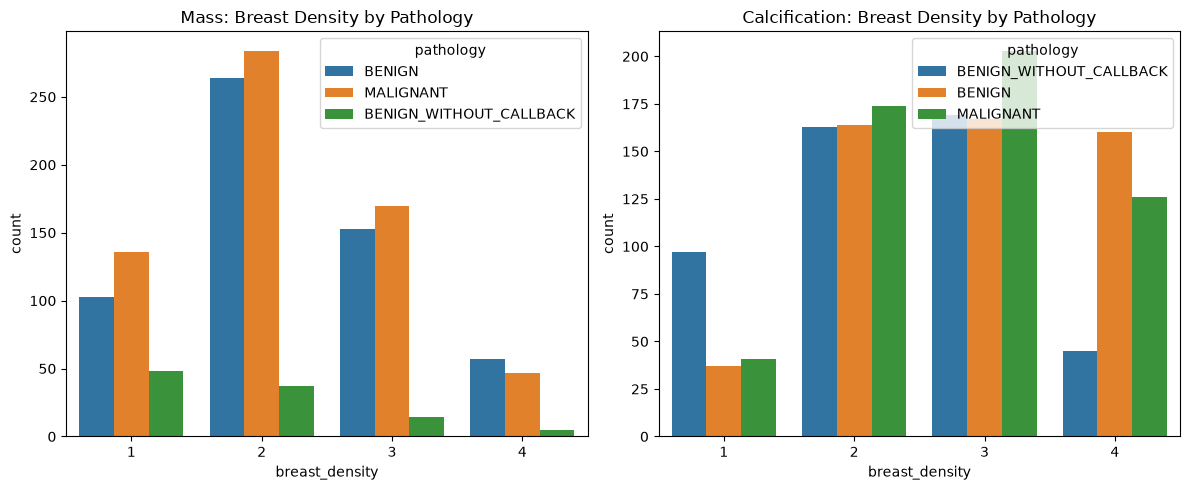

In [65]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(
    data=mass_df,
    x="breast_density",
    hue="pathology",
    ax=axes[0]
)
axes[0].set_title("Mass: Breast Density by Pathology")

sns.countplot(
    data=calc_df,
    x="breast_density",
    hue="pathology",
    ax=axes[1]
)
axes[1].set_title("Calcification: Breast Density by Pathology")

plt.tight_layout()
plt.show()

In [67]:
print (pd.crosstab(mass_df["breast_density"], mass_df["pathology"]))

pathology       BENIGN  BENIGN_WITHOUT_CALLBACK  MALIGNANT
breast_density                                            
1                  103                       48        136
2                  264                       37        284
3                  153                       14        170
4                   57                        5         47


In [68]:
print (pd.crosstab(
    calc_df["breast_density"],
    calc_df["pathology"]
))

pathology       BENIGN  BENIGN_WITHOUT_CALLBACK  MALIGNANT
breast_density                                            
1                   37                       97         41
2                  164                      163        174
3                  167                      169        203
4                  160                       45        126


### Key Findings

- Breast density category 2 is the most frequent category in the mass dataset.
- Breast density category 3 is the most frequent category in the calcification dataset.
- In the mass dataset, categories 1, 2, and 3 contain slightly more malignant than benign cases.
- In the calcification dataset, category 3 contains the highest number of malignant cases.
- Category 4 in the calcification dataset contains more benign than malignant cases.
- The relationship between breast density and pathology differs between the two datasets.

These findings highlight differences in pathology distributions across breast density categories and between the two datasets.

In [69]:
print (pd.crosstab(
    mass_df["assessment"],
    mass_df["pathology"]
))

pathology   BENIGN  BENIGN_WITHOUT_CALLBACK  MALIGNANT
assessment                                            
0              110                        0         19
1                0                        0          1
2               28                       49          0
3              189                       45         45
4              246                        8        279
5                4                        2        293


In [70]:
print (pd.crosstab(
    calc_df["assessment"],
    calc_df["pathology"]
))

pathology   BENIGN  BENIGN_WITHOUT_CALLBACK  MALIGNANT
assessment                                            
0               32                        0         31
2               14                      467          1
3               49                        4         36
4              431                        3        319
5                2                        0        157


### Key Findings

- Assessment category 5 is strongly represented among malignant cases in both datasets.
- Assessment category 4 contains a high number of both benign and malignant cases.
- Assessment category 2 is predominantly associated with BENIGN_WITHOUT_CALLBACK cases in the calcification dataset.
- Assessment category 2 contains no malignant cases in the mass dataset.
- The distribution of pathology across assessment categories differs between mass and calcification cases.

These findings highlight a strong association between assessment categories and pathology in both datasets.

In [71]:
print (pd.crosstab(
    mass_df["subtlety"],
    mass_df["pathology"]
))

pathology  BENIGN  BENIGN_WITHOUT_CALLBACK  MALIGNANT
subtlety                                             
0               2                        0          0
1              10                        1         30
2              40                        4         56
3             139                       17        101
4             180                       39        156
5             206                       43        294


In [72]:
print (pd.crosstab(
    calc_df["subtlety"],
    calc_df["pathology"]
))

pathology  BENIGN  BENIGN_WITHOUT_CALLBACK  MALIGNANT
subtlety                                             
1              44                        0         51
2             136                        0        106
3             165                      174        163
4             109                      121        116
5              74                      179        108


### Key Findings

- Subtlety category 1 contains slightly more malignant than benign cases.
- Subtlety category 2 contains more benign than malignant cases.
- Subtlety categories 3 and 4 show relatively balanced pathology distributions.
- Subtlety category 5 is predominantly associated with BENIGN_WITHOUT_CALLBACK cases.
- The relationship between subtlety and pathology differs between mass and calcification datasets.

These findings suggest that subtlety alone does not provide a consistent relationship with pathology across both datasets.

## 17. Correlation Analysis

**Objective:** Examine the relationships between numerical features in both datasets using correlation analysis.

The analysis focuses on:

- `breast_density`
- `assessment`
- `subtlety`

Correlation analysis will help identify potential relationships between these features.

Since these variables are ordinal, Spearman correlation will be used to evaluate monotonic relationships between them.

                breast_density  assessment  subtlety
breast_density        1.000000    0.027958 -0.310781
assessment            0.027958    1.000000  0.166847
subtlety             -0.310781    0.166847  1.000000


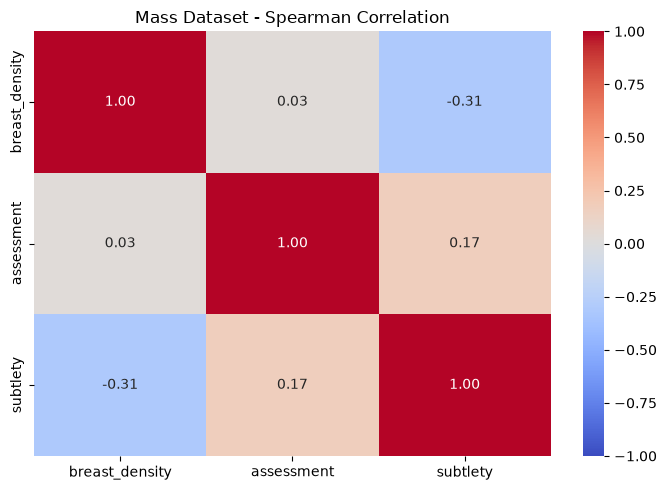

In [76]:
mass_corr = mass_df[
    ["breast_density", "assessment", "subtlety"]
].corr(method="spearman")

plt.figure(figsize=(7, 5))

sns.heatmap(
    mass_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Mass Dataset - Spearman Correlation")
plt.tight_layout()
plt.show()

### Key Findings

- Breast density and assessment have almost no correlation.
- Breast density and subtlety show a negative correlation (-0.31).
- Assessment and subtlety have a weak positive correlation (0.17).

Compared with the Calcification Dataset, the Mass Dataset shows a stronger negative relationship between breast density and subtlety.

No strong correlations were identified between the numerical features.

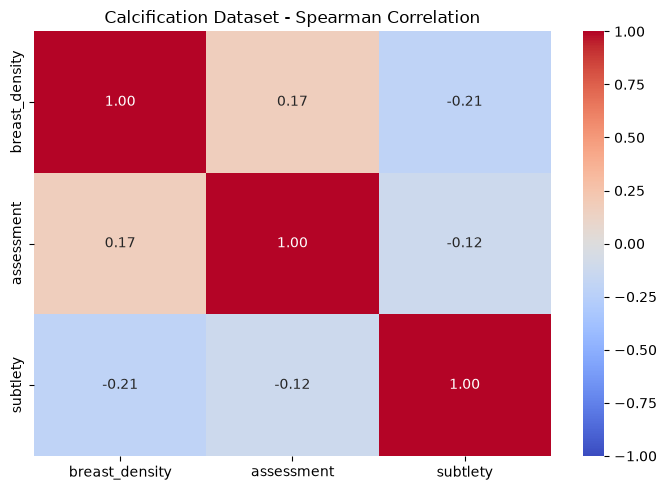

In [77]:
calc_corr = calc_df[
    ["breast_density", "assessment", "subtlety"]
].corr(method="spearman")


plt.figure(figsize=(7, 5))

sns.heatmap(
    calc_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Calcification Dataset - Spearman Correlation")
plt.tight_layout()
plt.show()

### Key Findings

- All feature pairs show weak correlations.
- Breast density and assessment have a weak positive association.
- Breast density and subtlety have a weak negative association.
- Assessment and subtlety have a very weak negative association.

No strong monotonic relationships were identified between the numerical features.

## 18. Data Understanding Summary

### Objective

Summarize the main findings obtained during the exploratory data analysis (EDA) of the Mass and Calcification datasets.

### Key Observations

- **Dataset size:** The Mass Dataset contains 1,318 records, while the Calcification Dataset contains 1,546 records.
- **Target variable:** Both datasets contain three pathology classes: BENIGN, BENIGN_WITHOUT_CALLBACK, and MALIGNANT.
- **Missing values:** Missing values were identified in clinical features, particularly `calc_distribution` (24.32%).
- **Duplicate records:** No exact duplicate rows were found. However, multiple records can belong to the same patient.
- **Categorical features:** Clinical descriptors such as mass shape, mass margins, calcification type, and calcification distribution show different patterns across pathology classes.
- **Numerical features:** Breast density, assessment, and subtlety have different distributions across the two datasets.
- **Correlation analysis:** Most numerical feature pairs show weak correlations, with no strong monotonic relationships identified.

### Conclusion

The exploratory analysis provided a better understanding of the dataset structure, feature distributions, missing values, and relationships between clinical descriptors and pathology.

These findings will guide the next phase: data cleaning, feature preparation, and machine learning model development.

Special attention will be given to missing values, repeated patient records, and the appropriate treatment of the three pathology categories.